Star Classification

- **Absolute Temperature (in K)**

- **Relative Luminosity (L/Lo)**

- **Relative Radius (R/Ro)**

- **Absolute Magnitude (Mv)**

- **Star Color** (white, Red, Blue, Yellow, yellow-orange etc)

- **Spectral Class** (O, B, A, F, G, K, M)

- **Star Type** (Red Dwarf, Brown Dwarf, White Dwarf, Main Sequence , SuperGiants, HyperGiants)

Models

1. **Random Forest**

2. **Logistic Regression**

3. **K-Nearest Neighbors**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/6 class csv.csv")
df.head()

,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color,Spectral Class
0,3068,0.002400,0.1700,16.12,0,Red,M
1,3042,0.000500,0.1542,16.60,0,Red,M
2,2600,0.000300,0.1020,18.70,0,Red,M
3,2800,0.000200,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/Lo)        240 non-null    float64
 2   Radius(R/Ro)            240 non-null    float64
 3   Absolute magnitude(Mv)  240 non-null    float64
 4   Star type               240 non-null    int64  
 5   Star color              240 non-null    object 
 6   Spectral Class          240 non-null    object 
dtypes: float64(3), int64(2), object(2)
memory usage: 13.3+ KB


In [3]:
for col in df.select_dtypes(include='object').columns:
    display(df[col].value_counts().to_frame(name='Count'))

,Count
Star color,
Red,112
Blue,55
Blue-white,26
Blue White,10
yellow-white,8
White,7
Blue white,3
Yellowish White,3
white,3


,Count
Spectral Class,
M,111
B,46
O,40
A,19
F,17
K,6
G,1


**Categorical Feature Distribution**

This section inspects the categorical columns in the dataset (columns with string/object type) to see how values are distributed

1. Counts the number of occurrences of each category

2. Converts the counts into a neat table for easy viewing

3. Helps understand the dataset before encoding for machine learning

**Example:**
- `Star color` → number of stars per color
- `Spectral Class` → number of stars per spectral class

This gives insight into the distribution and balance of categorical features

In [4]:
from sklearn.preprocessing import LabelEncoder

df = df.dropna().drop_duplicates()

le_color = LabelEncoder()
le_spectral = LabelEncoder()

df["Star color"] = le_color.fit_transform(df["Star color"])
df["Spectral Class"] = le_spectral.fit_transform(df["Spectral Class"])

X = df.drop(columns=["Star type"])
y = df["Star type"]

**Data Cleaning and Encoding**

1. **Remove missing values**

2. **Remove duplicates**

3. Label encode `Star color` and `Spectral Class`

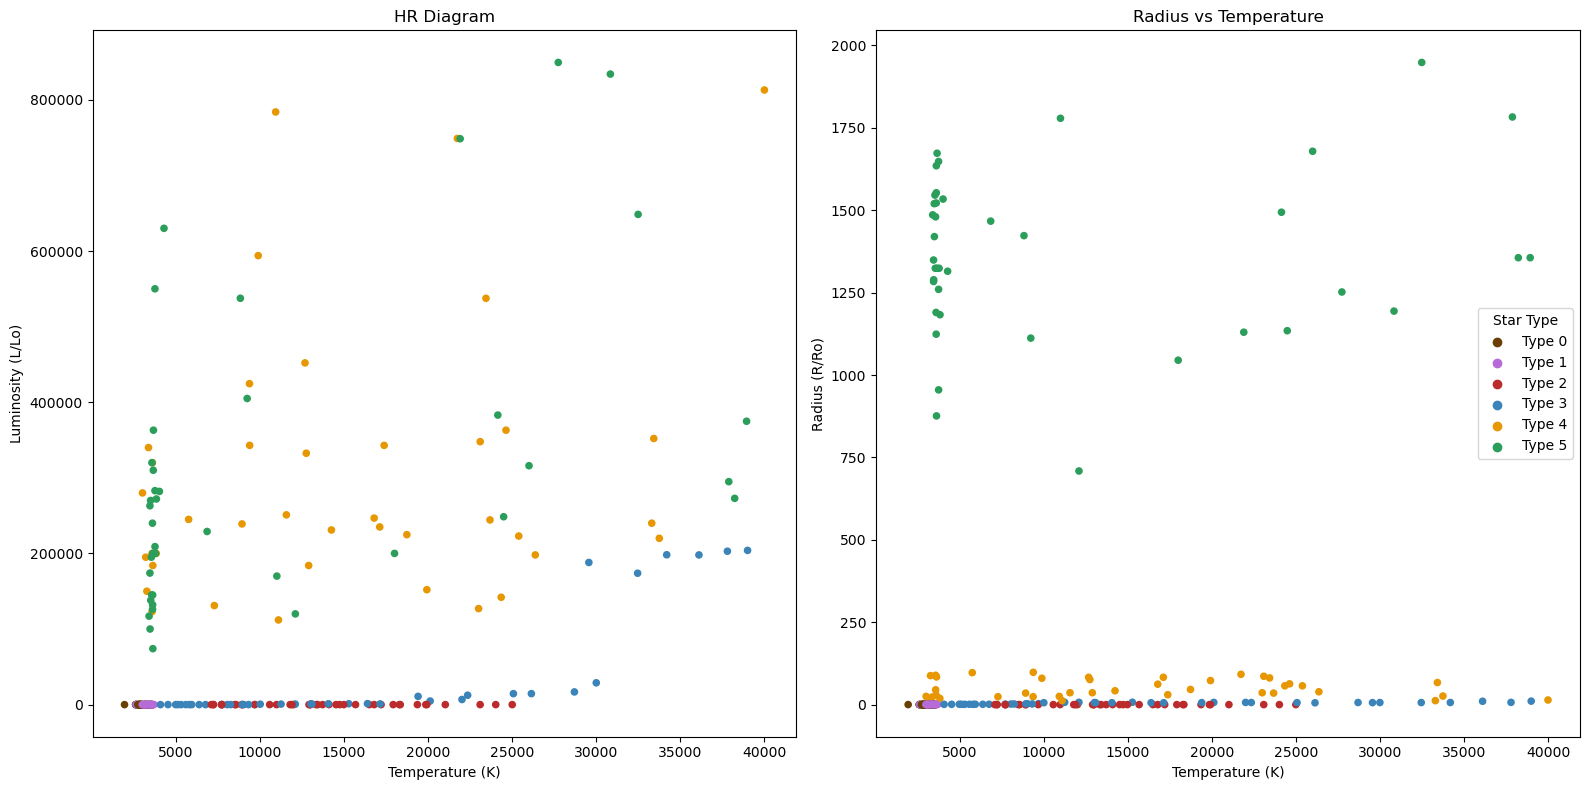

In [5]:
colors = {
    0: "#694002", 
    1: "#b76bd8", 
    2: "#bb2b2b", 
    3: "#3a84b9", 
    4: "#E79701", 
    5: "#2B9E5B"
}
point_colors = y.map(colors)

fig, axs = plt.subplots(1, 2, figsize=(16, 8))

axs[0].scatter(df['Temperature (K)'], df['Luminosity(L/Lo)'], c=point_colors, s=20)
axs[0].set_xlabel('Temperature (K)')
axs[0].set_ylabel('Luminosity (L/Lo)')
axs[0].set_title('HR Diagram')

axs[1].scatter(df['Temperature (K)'], df['Radius(R/Ro)'], c=point_colors, s=20)
axs[1].set_xlabel('Temperature (K)')
axs[1].set_ylabel('Radius (R/Ro)')
axs[1].set_title('Radius vs Temperature')

for t, c in colors.items():
    axs[1].scatter([], [], c=c, label=f"Type {t}")
axs[1].legend(title="Star Type")

plt.tight_layout()
plt.show()

**Stellar Feature Relationships**

How stars differ by type based on physical properties

1. HR Diagram (Temperature vs Luminosity): Reveals clusters of stars by brightness and temperature, a key tool in classifying stars

2. Radius vs Temperature: Highlights how star size varies with temperature, showing trends across different star types

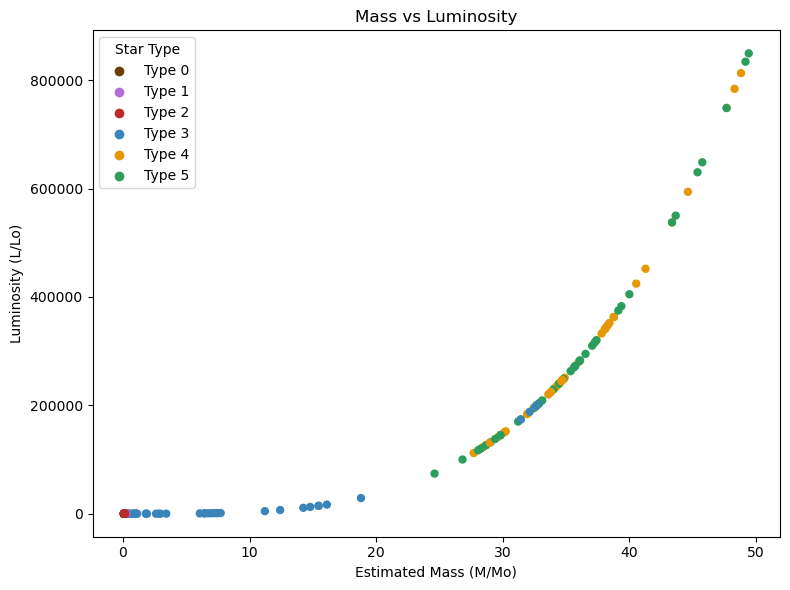

In [6]:
mass_estimate = df['Luminosity(L/Lo)'] ** (1/3.5)

plt.figure(figsize=(8,6))
plt.scatter(mass_estimate, df['Luminosity(L/Lo)'], c=point_colors, s=25)

plt.xlabel('Estimated Mass (M/Mo)')
plt.ylabel('Luminosity (L/Lo)')
plt.title('Mass vs Luminosity')

for t, c in colors.items():
    plt.scatter([], [], c=c, label=f"Type {t}")
plt.legend(title="Star Type")
plt.tight_layout()
plt.show()

**Mass vs Luminosity**

Estimates stellar mass from luminosity and compares it to actual luminosity

1. Illustrates the relationship between a star's mass and its brightness

2. Emphasizes that more massive stars tend to be more luminous

3. Shows differences between star types and their positions in stellar evolution

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=41
)

**Train-Test Split**

This divides the dataset into training and testing sets

1. Training set: Used to teach the models (80% of data)

2. Testing set: Used to evaluate model performance on unseen data (20% of data)

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Random Forest": RandomForestClassifier(random_state=41),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression())
    ]),
    "KNN": KNeighborsClassifier()
}

In [9]:
from sklearn.model_selection import cross_val_score

cv_results = {}

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    
    cv_results[name] = {
        "Mean Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    }

cv_table = pd.DataFrame(cv_results).T

display(cv_table)

,Mean Accuracy,Standard Deviation
Random Forest,0.991667,0.016667
Logistic Regression,0.945833,0.040825
KNN,0.641667,0.020412


**Cross-Validation Accuracy Comparison**

This table shows the **5-fold cross-validation results** for each model:

1. **Mean Accuracy**: The average accuracy across all 5 folds. Higher values indicate better overall performance.

2. **Standard Deviation**: The standard deviation of accuracy across folds. Lower values indicate more consistent performance.

From the table, we can see that:

1. **Random Forest** performs the best and is very consistent

2. **Logistic Regression** also performs well but with slightly higher variability

3. **KNN** performs the worst with lower mean accuracy


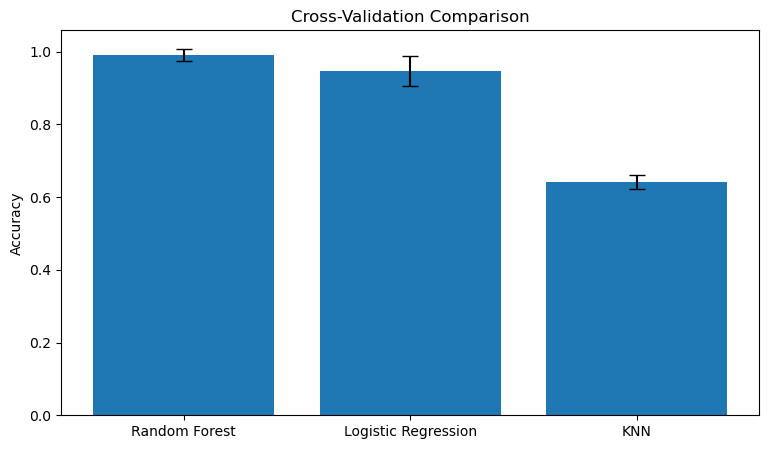

In [10]:
fig, ax = plt.subplots(figsize=(9,5))
names = list(cv_results.keys())
means = [cv_results[n]['Mean Accuracy'] for n in names]
stds  = [cv_results[n]['Standard Deviation'] for n in names]

ax.bar(names, means, yerr=stds, capsize=6)
ax.set_ylabel("Accuracy")
ax.set_title("Cross-Validation Comparison")
plt.show()

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

train_scores = []
test_scores = []

for name, model in models.items():
    model.fit(X_train, y_train)
    
    y_tr_pred = model.predict(X_train)
    y_te_pred = model.predict(X_test)

    train_scores.append({
        "Model": name,
        "Accuracy": accuracy_score(y_train, y_tr_pred),
        "Precision": precision_score(y_train, y_tr_pred, average="weighted"),
        "Recall": recall_score(y_train, y_tr_pred, average="weighted"),
        "F1": f1_score(y_train, y_tr_pred, average="weighted")
    })

    test_scores.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_te_pred),
        "Precision": precision_score(y_test, y_te_pred, average="weighted"),
        "Recall": recall_score(y_test, y_te_pred, average="weighted"),
        "F1": f1_score(y_test, y_te_pred, average="weighted")
    })

df_train = pd.DataFrame(train_scores)
df_test  = pd.DataFrame(test_scores)


print("=== Train Results ===")
display(df_train.style.hide(axis="index"))

print("=== Test Results ===")
display(df_test.style.hide(axis="index"))

=== Train Results ===


Model,Accuracy,Precision,Recall,F1
Random Forest,1.000000,1.000000,1.000000,1.000000
Logistic Regression,0.979167,0.980563,0.979167,0.979075
KNN,0.776042,0.785937,0.776042,0.773187


=== Test Results ===


Model,Accuracy,Precision,Recall,F1
Random Forest,1.000000,1.000000,1.000000,1.000000
Logistic Regression,0.937500,0.940972,0.937500,0.937834
KNN,0.604167,0.618676,0.604167,0.597926


**Train vs Test Performance Comparison**

This table shows the **evaluation metrics** for each model on both training and testing sets:

1. **Accuracy**: Overall proportion of correctly classified stars

2. **Precision**: How many predicted stars of a type were correct

3. **Recall**: How many stars of a type were correctly identified

4. **F1 Score**: Harmonic mean of precision and recall, balancing both

**Conclusion:**

1. **Random Forest** perfectly classifies both train and test sets (100%)

2. **Logistic Regression** performs very well, slightly lower on test (~94%)

3. **KNN** performs worst, with ~78% on train and ~60% on test, showing weaker generalization


In [12]:
from sklearn.metrics import classification_report

type_names = [f"Type {i}" for i in sorted(y.unique())]

tables = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    
    report_dict = classification_report(
        y_test,
        y_pred,
        target_names=type_names,
        output_dict=True
    )
    
    df = pd.DataFrame(report_dict).transpose()
    tables[name] = df

for model_name, df in tables.items():
    print(f"\n=== {model_name} ===")
    display(df)


=== Random Forest ===


,precision,recall,f1-score,support
Type 0,1.0,1.0,1.0,5.0
Type 1,1.0,1.0,1.0,10.0
Type 2,1.0,1.0,1.0,6.0
Type 3,1.0,1.0,1.0,9.0
Type 4,1.0,1.0,1.0,9.0
Type 5,1.0,1.0,1.0,9.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,48.0
weighted avg,1.0,1.0,1.0,48.0



=== Logistic Regression ===


,precision,recall,f1-score,support
Type 0,0.833333,1.000000,0.909091,5.0000
Type 1,0.900000,0.900000,0.900000,10.0000
Type 2,1.000000,1.000000,1.000000,6.0000
Type 3,0.888889,0.888889,0.888889,9.0000
Type 4,1.000000,0.888889,0.941176,9.0000
Type 5,1.000000,1.000000,1.000000,9.0000
accuracy,0.937500,0.937500,0.937500,0.9375
macro avg,0.937037,0.946296,0.939859,48.0000
weighted avg,0.940972,0.937500,0.937834,48.0000



=== KNN ===


,precision,recall,f1-score,support
Type 0,0.500000,0.800000,0.615385,5.000000
Type 1,0.857143,0.600000,0.705882,10.000000
Type 2,0.666667,1.000000,0.800000,6.000000
Type 3,0.750000,0.666667,0.705882,9.000000
Type 4,0.375000,0.333333,0.352941,9.000000
Type 5,0.500000,0.444444,0.470588,9.000000
accuracy,0.604167,0.604167,0.604167,0.604167
macro avg,0.608135,0.640741,0.608446,48.000000
weighted avg,0.618676,0.604167,0.597926,48.000000


**Classification Report**

1. **Random Forest**: Perfect classification across all star types 

3. **Logistic Regression**: High performance, slight drops on some classes 

4. **KNN**: Lower performance, struggles with certain star types

**Conclusion:** Ensemble methods like Random Forest handle this dataset best, while simpler or distance-based models may underperform on imbalanced or overlapping classes

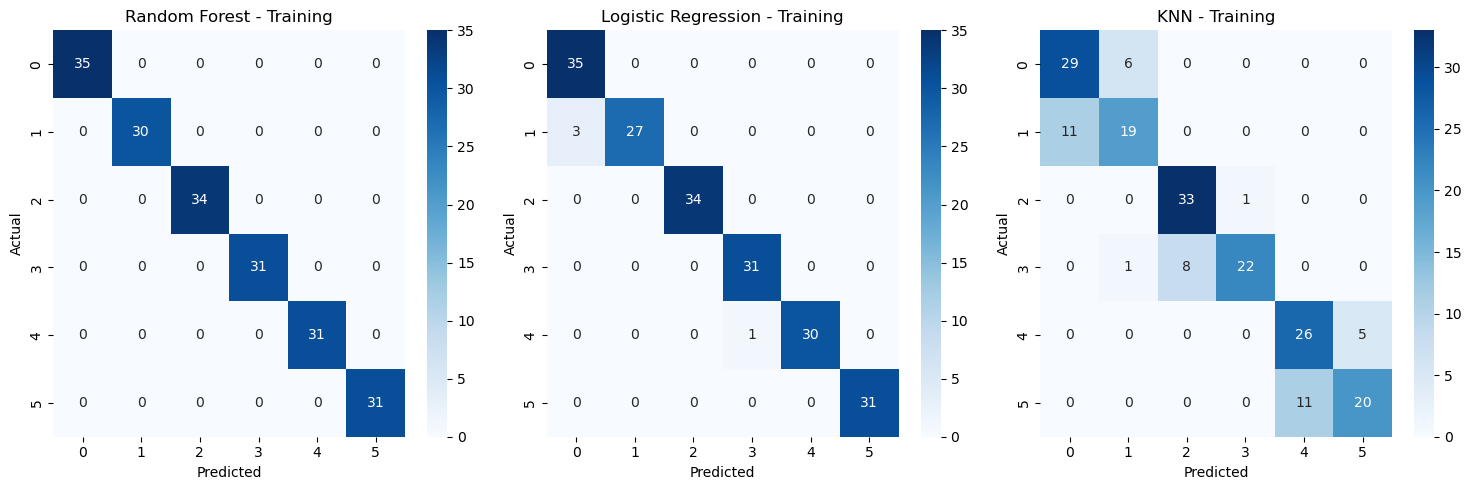

In [13]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for i, name in enumerate(models):
    y_train_pred = models[name].predict(X_train)
    cm_train = confusion_matrix(y_train, y_train_pred)
    
    sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', ax=axs[i])
    axs[i].set_title(f"{name} - Training")
    axs[i].set_xlabel("Predicted")
    axs[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

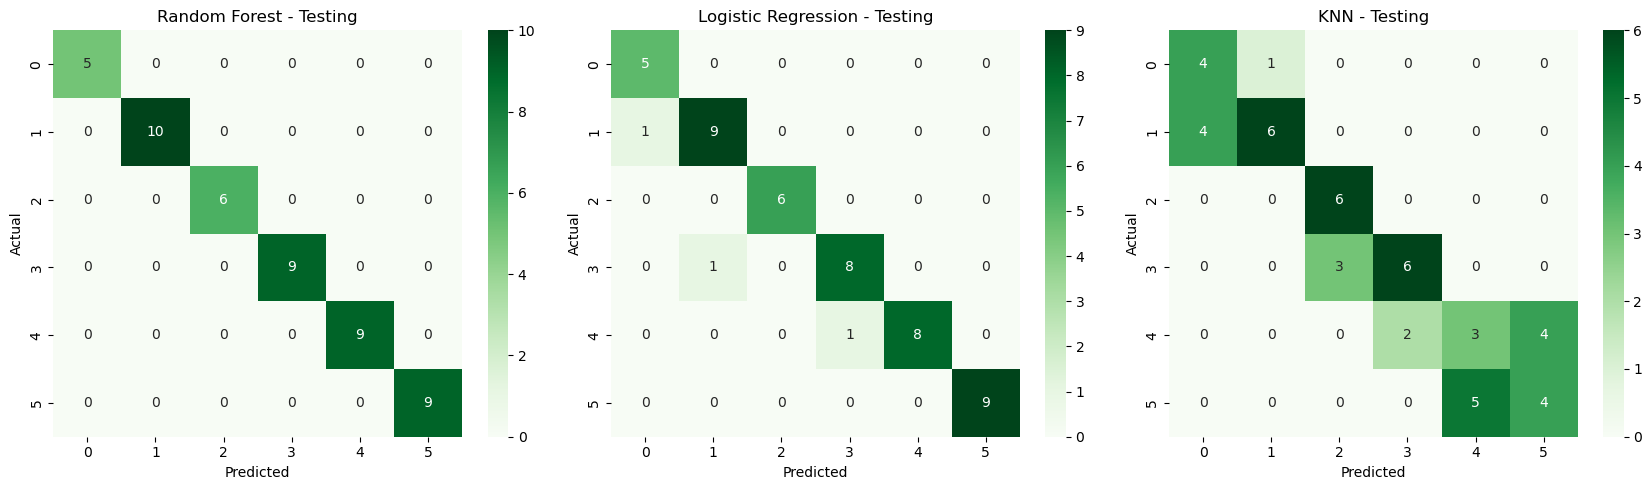

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(17,5))

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axs[i])
    axs[i].set_title(f"{name} - Testing")
    axs[i].set_xlabel("Predicted")
    axs[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

**Random Forest Classifier**

1. Training: Scores a perfect 100% across accuracy, precision, recall, and F1. It classifies every training sample correctly, meaning it fits the training data completely.

2. Testing: Performance stays perfect on the test set as well. No drop-off between training and testing suggests extremely strong generalization on this dataset, with no visible signs of overfitting.

---

Logistic Regression

1. Training: Also achieves perfect performance on the training data - 100% accuracy, precision, recall, and F1. The model separates the classes cleanly with no misclassifications.

2. Testing: Testing metrics remain high but not perfect (~95–96%). A small number of errors appear, but the model generalizes well overall. The slight drop from training to testing is normal for linear models on more complex datasets.

---

K-Nearest Neighbors (KNN)

1. Training: Shows moderate performance (~77–78% across metrics). KNN doesn’t overfit the training data heavily; instead, it reflects the natural variability and overlap in the feature space.

2. Testing: Performance declines noticeably (~60% accuracy, similar drops in precision, recall, and F1). This gap between train and test suggests the model struggles with generalization and is sensitive to noise and data distribution differences.

---

**Summary**

1. **Random Forest** is the strongest overall, with perfect results on both training and testing  

2. **Logistic Regression** generalizes well, with only a slight performance drop on unseen data 

3. **KNN** performs the weakest, showing a significant decrease from training to testing, indicating difficulty adapting to new samples

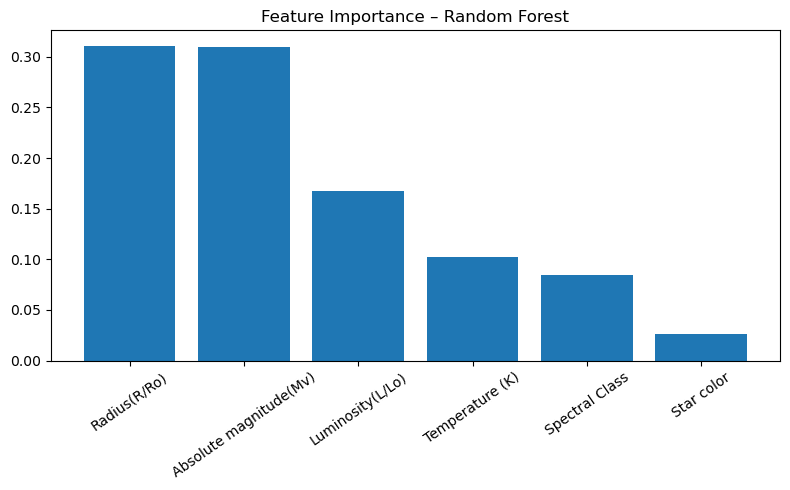

In [15]:
importances = models["Random Forest"].feature_importances_
idx = np.argsort(importances)[::-1]

plt.figure(figsize=(8,5))
plt.bar(X.columns[idx], importances[idx])
plt.title("Feature Importance – Random Forest")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

**Random Forest Feature Importance**

The chart ranks features by how much they influenced the Random Forest’s decisions

1. **High importance** → the model relied on this feature heavily 

2. **Low importance** → smaller impact on predictions


In [16]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

gs = GridSearchCV(
    RandomForestClassifier(random_state=41),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

gs.fit(X_train, y_train)

best_params_df = pd.DataFrame(gs.best_params_, index=[0])
best_params_df["Best CV Score"] = gs.best_score_

display(best_params_df.style.hide(axis="index"))

max_depth,min_samples_leaf,min_samples_split,n_estimators,Best CV Score
10,1,2,50,0.994737


**Random Forest Hyperparameter Tuning**

- **Best Parameters:** The grid search found that a forest with **50 trees**, **max depth of 10**, **minimum 2 samples to split a node**, and **1 sample per leaf** gives the best performance

- **Best CV Score:** Using these settings, the model achieves **~99.5% accuracy** on 5-fold cross-validation

**Conclusion:** A moderately deep forest with a small number of trees is sufficient for this dataset to achieve near-perfect classification


In [17]:
import joblib

joblib.dump(gs.best_estimator_, "star_classifier_optimized.pkl")
joblib.dump(models["Random Forest"], "star_classifier_original.pkl")
joblib.dump(le_color, "le_color.pkl")
joblib.dump(le_spectral, "le_spectral.pkl")

['le_spectral.pkl']